In [1]:
import torch
import numpy as np
from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
import torch.nn.functional as F
from tqdm import tqdm

In [ ]:
OCTA_ARI_O = 0
OCTA_ARI_A = 0
count = 0
for i in tqdm(range(3100,3200)):
    for j in range(60):
        gt = np.array(Image.open(f"128x128/GT_mask/3100-3199/{i}_{j:02d}.png")).flatten()
        pred = np.array( Image.open(f"128x128/mask/{i}/{j:02d}.png")).flatten()

        pred_flat = pred.reshape(-1)
        gt_flat   = gt.reshape(-1)

        # optional: ignore background in GT
        mask_ARI_O = gt_flat != 0
        pred_flat_O = pred_flat[mask_ARI_O ]
        gt_flat_O   = gt_flat[mask_ARI_O ]

        # remap pred values to consecutive 0..(n-1) labels (recommended)
        _, pred_labels = np.unique(pred_flat_O, return_inverse=True)

        ari_O = adjusted_rand_score(gt_flat_O, pred_labels)

        _, pred_labels = np.unique(pred_flat, return_inverse=True)
        ari_A = adjusted_rand_score(gt_flat, pred_labels)

        OCTA_ARI_O += ari_O
        OCTA_ARI_A += ari_A
        count +=1 

print(OCTA_ARI_O/count)

print(OCTA_ARI_A/count)

In [ ]:
OCTB_ARI_O = 0
OCTB_ARI_A = 0
count = 0
for i in tqdm(range(4900,5000)):
    for j in range(60):
        gt = np.array(Image.open(f"128x128/GT_mask/4900-4999/{i}_{j:02d}.png")).flatten()
        pred = np.array( Image.open(f"128x128/mask/{i}/{j:02d}.png")).flatten()

        pred_flat = pred.reshape(-1)
        gt_flat   = gt.reshape(-1)

        # optional: ignore background in GT
        mask_ARI_O = gt_flat != 0
        pred_flat_O = pred_flat[mask_ARI_O ]
        gt_flat_O   = gt_flat[mask_ARI_O ]

        # remap pred values to consecutive 0..(n-1) labels (recommended)
        _, pred_labels = np.unique(pred_flat_O, return_inverse=True)

        ari_O = adjusted_rand_score(gt_flat_O, pred_labels)

        _, pred_labels = np.unique(pred_flat, return_inverse=True)
        ari_A = adjusted_rand_score(gt_flat, pred_labels)

        OCTB_ARI_O += ari_O
        OCTB_ARI_A += ari_A
        count +=1 

print(OCTB_ARI_O/count)
print(OCTB_ARI_A/count)

In [ ]:
OCTA_AMI_O = 0.0
OCTA_AMI_A = 0.0
count = 0

for i in tqdm(range(3100, 3200)):
    for j in range(60):
        gt = np.array(Image.open(f"128x128/GT_mask/3100-3199/{i}_{j:02d}.png")).reshape(-1)
        pred = np.array(Image.open(f"128x128/mask/{i}/{j:02d}.png")).reshape(-1)

        # Foreground-only (ignore GT background 0)
        m = gt != 0
        gt_O = gt[m]
        pred_O = pred[m]
        _, pred_O_labels = np.unique(pred_O, return_inverse=True)

        ami_O = adjusted_mutual_info_score(gt_O, pred_O_labels, average_method="arithmetic")

        # All pixels
        _, pred_A_labels = np.unique(pred, return_inverse=True)
        ami_A = adjusted_mutual_info_score(gt, pred_A_labels, average_method="arithmetic")

        OCTA_AMI_O += ami_O
        OCTA_AMI_A += ami_A
        count += 1

print("Mean AMI (foreground):", OCTA_AMI_O / count)
print("Mean AMI (all pixels):", OCTA_AMI_A / count)

In [ ]:
OCTB_AMI_O = 0.0
OCTB_AMI_A = 0.0
count = 0

for i in tqdm(range(4900, 5000)):
    for j in range(60):
        gt = np.array(Image.open(f"128x128/GT_mask/4900-4999/{i}_{j:02d}.png")).reshape(-1)
        pred = np.array(Image.open(f"128x128/mask/{i}/{j:02d}.png")).reshape(-1)

        # Foreground-only (ignore GT background 0)
        m = gt != 0
        gt_O = gt[m]
        pred_O = pred[m]
        _, pred_O_labels = np.unique(pred_O, return_inverse=True)

        ami_O = adjusted_mutual_info_score(gt_O, pred_O_labels, average_method="arithmetic")

        # All pixels
        _, pred_A_labels = np.unique(pred, return_inverse=True)
        ami_A = adjusted_mutual_info_score(gt, pred_A_labels, average_method="arithmetic")

        OCTB_AMI_O += ami_O
        OCTB_AMI_A += ami_A
        count += 1

print("Mean AMI (foreground):", OCTB_AMI_O / count)
print("Mean AMI (all pixels):", OCTB_AMI_A / count)

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/scratch/work/hsut2/SA-OCL")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [ ]:
from testing_models.contrasa_base import SlotContrastModel as contrasa
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = contrasa(num_slots=15,      # Adjust based on max objects in your OCT scenes
        slot_dim=128,      # 128 for Base
        feat_dim=768,
        img_size=224, 
        patch_size=14).to(device)
model.load_state_dict(torch.load(str(PROJECT_ROOT / "testing_models/contrasa_base/epoch_100.pth"),weights_only=True))

In [5]:
import glob
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms
import os
class OCTScenesDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        """
        Adapts 'OCTScenes_grouped' to the paper's specific format.
        Paper Config: Training Segment Length = 4 [Table S1]
        """
        self.root_dir = root_dir
        self.transform = transform
        self.sequence_length = 60  # STRICTLY 4 based on Table S1 
        self.samples = []

        scene_paths = sorted(glob.glob(os.path.join(root_dir, "*")))
        for scene_path in scene_paths:
            scecne =scene_path.split("/")[-1]
            if int(scecne) < 4900 or int(scecne)>4999:
                continue
            if not os.path.isdir(scene_path): continue
            
            # Sort frames numerically
            frames = sorted(
                glob.glob(os.path.join(scene_path, "*.png")),
                key=lambda x: int(''.join(filter(str.isdigit, os.path.basename(x))))
            )
            
            # Create sliding windows of length 4
            # We can stride by 1 to maximize data, or 4 to avoid overlap.
            # Paper likely strides by 4 or uses random sampling. Stride=4 is safer for diversity.
            stride = 4
            if len(frames) >= self.sequence_length:
                for i in range(0, len(frames) - self.sequence_length + 1):
                    self.samples.append(frames[i : i + self.sequence_length])

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        frame_paths = self.samples[idx]
        scecne =frame_paths[0].split("/")[-2]
        frames = []
        for p in frame_paths:
            img = Image.open(p).convert("RGB")
            if self.transform:
                img = self.transform(img)
            frames.append(img)
            
        return torch.stack(frames), scecne # (T=4, C, H, W)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
data_root = "128x128/image" # Update this path

dataset = OCTScenesDataset(
    root_dir=data_root,
    transform=train_transform
)

# Batch size: Paper uses batch size 64 across GPUs. 
# For a single GPU, try 4 or 8 depending on VRAM (DINO is heavy).
dataloader = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=4)

# 2. Setup Model (using the class we defined in the previous answer)
# Ensure you have the 'timm' version of the class loaded
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
model.eval()
OCTA_ARI_A = 0
OCTA_ARI_O = 0
for data,scecne in tqdm(dataloader):
    data=data.to(device)
    out = model(data)
    masks= out["masks"].squeeze(0).squeeze(-1).view(60,15,16,16).view(900,1,16,16)
    scecne = int(scecne[0])
    masks = F.interpolate(
        masks,
        size=(128, 128),
        mode="bilinear",
        align_corners=False
    ).view(60,15,128,128,1).squeeze(-1).detach().cpu()

    pred_labels_all = masks.argmax(dim=1).cpu().numpy()   # (60, H, W)

    for j in range(60):
        gt = np.array(Image.open(f"128x128/GT_mask/4900-4999/{scecne}_{j:02d}.png"))
        if gt.ndim == 3:
            gt = gt[..., 0]  # in case it's RGB

        gt_flat   = gt.reshape(-1)
        pred_flat = pred_labels_all[j].reshape(-1)

        # ignore background
        mask_fg = gt_flat != 0
        ari_O = adjusted_rand_score(gt_flat[mask_fg], pred_flat[mask_fg])
        ari_A = adjusted_rand_score(gt_flat, pred_flat)

        OCTA_ARI_O += ari_O
        OCTA_ARI_A += ari_A
        count += 1
print("Mean ARI (foreground):", OCTA_ARI_O / count)
print("Mean ARI (all pixels):", OCTA_ARI_A / count)
    

In [3]:
import re, io, os, glob
import webdataset as wds
from PIL import Image
import torch
from torchvision import transforms

In [4]:
from testing_models.contrasa_base import SlotContrastModel as contrasa
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = contrasa(num_slots=11,      # Adjust based on max objects in your OCT scenes
        slot_dim=128,      # 128 for Base
        feat_dim=768,
        img_size=518, 
        patch_size=14).to(device)
model.load_state_dict(torch.load(str(PROJECT_ROOT / "testing_models/contrasa_base_518/epoch_100.pth"),weights_only=True))

/scratch/work/hsut2/.conda_envs/gaussian_grouping/lib/python3.8/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


<All keys matched successfully>

In [4]:
def parse_chunk_scene_frame(key: str):
    # key like: "segment/4900-4999/4918_53"
    parts = key.split("/")
    chunk = parts[1]                 # "4900-4999"
    base  = parts[-1]                # "4918_53"

    m = re.match(r"(\d+)_([0-9]+)$", base)
    if m is None:
        return chunk, None, -1

    scene_id = m.group(1)            # "4918"
    frame_id = int(m.group(2))       # 53
    return chunk, scene_id, frame_id
def decode_key_png_mask(t):
    key, png = t
    # load as grayscale mask
    gt = np.array(Image.open(io.BytesIO(png)))
    if gt.ndim == 3:
        gt = gt[..., 0]
    return key, gt  # key str, gt HxW uint8/int
def keep_only_chunks(allowed_chunks):
    def _filter(kv):
        key, _ = kv
        parts = key.split("/")
        if len(parts) < 3:
            return False
        chunk = parts[1]   # e.g. "4900-4999"
        return chunk in allowed_chunks
    return _filter

def group_by_scene_stack_masks(samples, frames_per_scene=60):
    current = None
    bucket = []

    def flush(chunk, scene_id, bucket):
        # sort by frame index
        bucket.sort(key=lambda x: parse_chunk_scene_frame(x[0])[2])
        bucket = bucket[:frames_per_scene]
        gts = [gt for _, gt in bucket]                 # list of HxW
        gt_stack = torch.from_numpy(np.stack(gts))     # (T,H,W)
        return chunk, scene_id, gt_stack

    for key, gt in samples:
        chunk, scene_id, frame_id = parse_chunk_scene_frame(key)
        if scene_id is None:
            continue  # skip weird keys like directory placeholders

        scene_key = (chunk, scene_id)
        if current is None:
            current = scene_key

        if scene_key != current:
            yield flush(current[0], current[1], bucket)
            current = scene_key
            bucket = []

        bucket.append((key, gt))

    if bucket and current is not None:
        yield flush(current[0], current[1], bucket)
    
def make_gt_loader(
    tar_path,
    batch_size=1,
    num_workers=0,
    frames_per_scene=60,
    allowed_chunks=None,
):
    ds = (
        wds.WebDataset([tar_path], shardshuffle=False, empty_check=False)
        .to_tuple("__key__", "png")
        .select(keep_only_chunks(allowed_chunks) if allowed_chunks else lambda _: True)
        .map(decode_key_png_mask)
        .compose(lambda it: group_by_scene_stack_masks(it, frames_per_scene=frames_per_scene))
    )
    return wds.WebLoader(ds, batch_size=batch_size, num_workers=num_workers)

gt_loader = make_gt_loader(
    "640x480/segment_640x480.tar.gz",
    batch_size=1,
    num_workers=0,
    frames_per_scene=60,
    allowed_chunks={"4900-4999"},   # <-- only this chunk
)


In [9]:


train_transform = transforms.Compose([
    transforms.Resize((518, 518)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

def frame_index(key: str) -> int:
    nums = re.findall(r"\d+", key.split("/")[-1])
    return int(nums[-1]) if nums else -1

def decode_key_png(t):
    key, png = t
    img = Image.open(io.BytesIO(png)).convert("RGB")
    return key, img

def group_by_scene_and_stack(samples, transform, frames_per_scene=60):
    current_scene = None
    bucket = []

    def scene_of(key: str) -> str:
        return key.split("/", 1)[0] if "/" in key else key.split("_", 1)[0]

    def flush(scene, bucket):
        bucket.sort(key=lambda x: frame_index(x[0]))
        bucket = bucket[:frames_per_scene]
        frames = [transform(im) for _, im in bucket]
        return scene, torch.stack(frames)  # (scene, (T,C,H,W))

    for key, img in samples:
        scene = scene_of(key)
        if current_scene is None:
            current_scene = scene

        if scene != current_scene:
            yield flush(current_scene, bucket)
            current_scene = scene
            bucket = []

        bucket.append((key, img))

    if bucket:
        yield flush(current_scene, bucket)
def make_loader(tars, transform, batch_size=1, num_workers=4, frames_per_scene=60, shuffle_shards=False):
    ds = (
        wds.WebDataset(tars, shardshuffle=shuffle_shards)
        .to_tuple("__key__", "png")   # <-- FIX: use __key__ (always exists)
        .map(decode_key_png)
        .compose(lambda it: group_by_scene_and_stack(it, transform=transform, frames_per_scene=frames_per_scene))
    )
    return wds.WebLoader(ds, batch_size=batch_size, num_workers=num_workers)

tar_paths = sorted(glob.glob("640x480/compressed/scenes_0049.tar"))
tar_paths = [os.path.abspath(p) for p in tar_paths]

test_loader = make_loader(
    tar_paths,
    transform=train_transform,
    batch_size=1,
    num_workers=0,
    frames_per_scene=10,
)


In [10]:
import tarfile, io, re
def load_rgb_scene_from_tar(tar_path, scene_id: str, transform, T=60):
    frames = []
    with tarfile.open(tar_path, "r:*") as tf:
        for j in range(T):
            name = f"{scene_id}/{j:02d}.png"   # e.g. 4900/03.png
            f = tf.extractfile(name)
            if f is None:
                raise FileNotFoundError(f"Missing RGB frame {name} in {tar_path}")
            img = Image.open(io.BytesIO(f.read())).convert("RGB")
            frames.append(transform(img))
    return torch.stack(frames)  # (T,C,H,W)
def load_gt_scene_from_tar(tar_path, scene_id: str, chunk="4900-4999", T=60):
    # We’ll fill a list of length T, then stack at the end
    gts = [None] * T

    prefix = f"segment/{chunk}/{scene_id}_"
    with tarfile.open(tar_path, "r:*") as tf:
        # iterate members and pick only those belonging to this scene
        for m in tf.getmembers():
            if not m.isfile():
                continue
            name = m.name  # e.g. segment/4900-4999/4900_21.png
            if not name.startswith(prefix) or not name.endswith(".png"):
                continue

            # parse frame index from ".../{scene_id}_{frame}.png"
            base = name.split("/")[-1]          # 4900_21.png
            frame_str = base.split("_", 1)[1].split(".", 1)[0]
            j = int(frame_str)

            if 0 <= j < T:
                f = tf.extractfile(m)
                gt = np.array(Image.open(io.BytesIO(f.read())))
                if gt.ndim == 3:
                    gt = gt[..., 0]
                gts[j] = gt

    # sanity check
    missing = [i for i, x in enumerate(gts) if x is None]
    if missing:
        raise FileNotFoundError(f"Missing GT masks for scene {scene_id} frames: {missing[:10]}... (total {len(missing)})")

    return torch.from_numpy(np.stack(gts))  # (T,H,W)
def load_scene_pair(
    rgb_tar=str(PROJECT_ROOT / "data/OCTScenes_grouped/640x480/compressed/scenes_0049.tar"),
    gt_tar=str(PROJECT_ROOT / "data/OCTScenes_grouped/640x480/segment_640x480.tar.gz"),
    scene_id="4900",
    transform=None,
    chunk="4900-4999",
    T=60
):
    rgb = load_rgb_scene_from_tar(rgb_tar, scene_id, transform, T=T)   # (T,C,H,W)
    gt  = load_gt_scene_from_tar(gt_tar, scene_id, chunk=chunk, T=T)   # (T,H,W)
    return scene_id, rgb, gt



def iter_scenes(
    rgb_tar,
    gt_tar,
    scene_ids,
    transform,
    chunk="4900-4999",
    T=60,
):
    for scene_id in scene_ids:
        rgb = load_rgb_scene_from_tar(
            rgb_tar,
            scene_id=str(scene_id),
            transform=transform,
            T=T,
        )
        gt = load_gt_scene_from_tar(
            gt_tar,
            scene_id=str(scene_id),
            chunk=chunk,
            T=T,
        )
        yield scene_id, rgb, gt

In [ ]:
OCTB_ARI_O = 0 
OCTB_ARI_A = 0
count = 0
for scene_id, rgb, gt in iter_scenes(
    rgb_tar="640x480/compressed/scenes_0049.tar",
    gt_tar="640x480/segment_640x480.tar.gz",
    scene_ids=range(4900, 5000),
    transform=train_transform,
    chunk="4900-4999",
    T=10,
):

    data=rgb.to(device).unsqueeze(0)
    out = model(data)

    masks= out["masks"].squeeze(0).squeeze(-1).view(10,11,37,37).view(110,1,37,37)
    masks = F.interpolate(
        masks,
        size=(480, 640),
        mode="bilinear",
        align_corners=False
    ).view(10,11,480, 640,1).squeeze(-1).detach().cpu()

    pred_labels_all = masks.argmax(dim=1).cpu().numpy()   # (60, H, W)
    
    for j in range(10):
        gt_msk = np.array(gt[j])
        if gt_msk.ndim == 3:
            gt_msk = gt_msk[..., 0]  # in case it's RGB

        gt_flat   = gt_msk.reshape(-1)
        pred_flat = pred_labels_all[j].reshape(-1)

        # ignore background
        mask_fg = gt_flat != 0
        ari_O = adjusted_rand_score(gt_flat[mask_fg], pred_flat[mask_fg])
        ari_A = adjusted_rand_score(gt_flat, pred_flat)

        OCTB_ARI_O += ari_O
        OCTB_ARI_A += ari_A
        count += 1
print(OCTB_ARI_O/count, OCTB_ARI_A/count)

In [8]:
OCTB_ARI_O = 0 
OCTB_ARI_A = 0
count = 0
for scene_id, rgb, gt in iter_scenes(
    rgb_tar="640x480/compressed/scenes_0049.tar",
    gt_tar="640x480/segment_640x480.tar.gz",
    scene_ids=range(4900, 5000),
    transform=train_transform,
    chunk="4900-4999",
    T=60,
):

    for j in range(60):
        deva = np.array(Image.open(f"640x480/mask/{scene_id}/{j:02d}.png")).reshape(-1)
        gt_msk = np.array(gt[j])
        if gt_msk.ndim == 3:
            gt_msk = gt_msk[..., 0]  # in case it's RGB

        gt_flat   = gt_msk.reshape(-1)
        pred_flat =  deva.reshape(-1)

        # ignore background
        mask_fg = gt_flat != 0
        ari_O = adjusted_rand_score(gt_flat[mask_fg], pred_flat[mask_fg])
        ari_A = adjusted_rand_score(gt_flat, pred_flat)

        OCTB_ARI_O += ari_O
        OCTB_ARI_A += ari_A
        count += 1
print(OCTB_ARI_O/count, OCTB_ARI_A/count)

0.6907185161784484 0.040191509294302874


In [11]:
OCTB_AMI_O = 0 
OCTB_AMI_A = 0
count = 0
for scene_id, rgb, gt in iter_scenes(
    rgb_tar="640x480/compressed/scenes_0049.tar",
    gt_tar="640x480/segment_640x480.tar.gz",
    scene_ids=range(4900, 5000),
    transform=train_transform,
    chunk="4900-4999",
    T=60,
):

    for j in tqdm(range(60)):
        deva = np.array(Image.open(f"640x480/mask/{scene_id}/{j:02d}.png")).reshape(-1)
        gt_msk = np.array(gt[j])
        if gt_msk.ndim == 3:
            gt_msk = gt_msk[..., 0]  # in case it's RGB

        gt_flat   = gt_msk.reshape(-1)
        pred_flat =  deva.reshape(-1)

        # ignore background
        mask_fg = gt_flat != 0
        ari_O = adjusted_mutual_info_score(gt_flat[mask_fg], pred_flat[mask_fg])
        ari_A =  adjusted_mutual_info_score(gt_flat, pred_flat)

        OCTB_AMI_O += ari_O
        OCTB_AMI_A += ari_A
        count += 1
print(OCTB_AMI_O/count, OCTB_AMI_A/count)

100%|██████████| 60/60 [00:16<00:00,  3.72it/s]

0.7660088210738967 0.17093334975635197


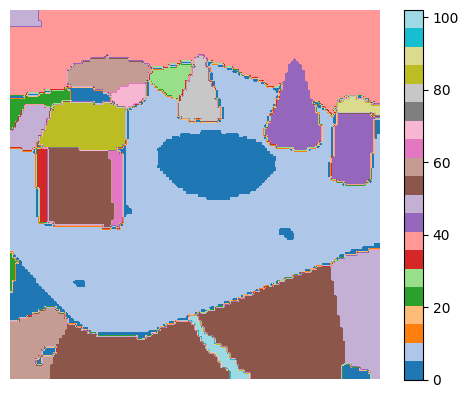

In [5]:
import matplotlib.pyplot as plt
import imageio.v2 as imageio
import numpy as np
img = imageio.imread("128x128/mask/4966/00.png")  # numpy array

plt.imshow(img, cmap="tab20")   # good for label maps
plt.axis("off")
plt.colorbar()
plt.show()

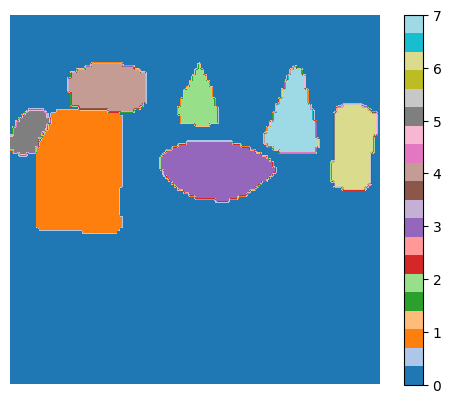

In [6]:
img = imageio.imread("128x128/GT_mask/4900-4999/4966_00.png")  # numpy array

plt.imshow(img, cmap="tab20")   # good for label maps
plt.axis("off")
plt.colorbar()
plt.show()

(128, 128) uint16


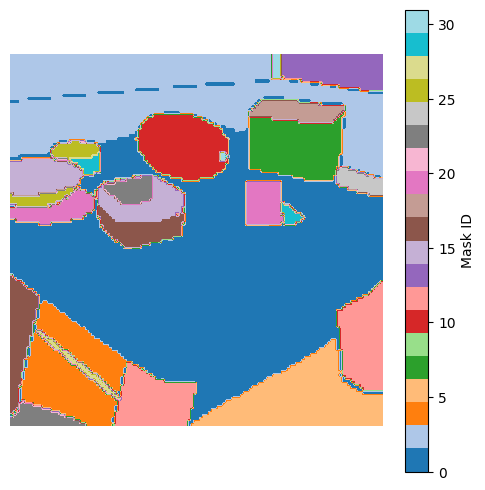

In [7]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# load PNG mask
mask = np.array(Image.open("128x128/SAM_mask/3199/00.png"))

print(mask.shape, mask.dtype)  # sanity check

plt.figure(figsize=(6, 6))
plt.imshow(mask, cmap="tab20")
plt.colorbar(label="Mask ID")
plt.axis("off")
plt.show()


In [6]:
from PIL import Image
import numpy as np

m = np.array(Image.open("128x128/SAM_mask/3193/00.png"))
print(m.shape, m.dtype, int(m.min()), int(m.max()))
u = np.unique(m)
print("unique_count:", len(u), "first20:", u)

(128, 128) uint16 0 34
unique_count: 33 first20: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 32 33 34]


In [5]:
from PIL import Image

img = Image.open("128x128/GT_mask/3100-3199/3100_00.png")
print(img.mode) 
index = img.getpixel((0, 0))
print(index)  # this is the palette index


L
0


Opening 128x128/depth_128x128.tar.gz for visualization...
dtype: uint16
min: 0
max: 1981
mean: 835.6823120117188
dtype: uint16
min: 0
max: 2028
mean: 862.9827880859375


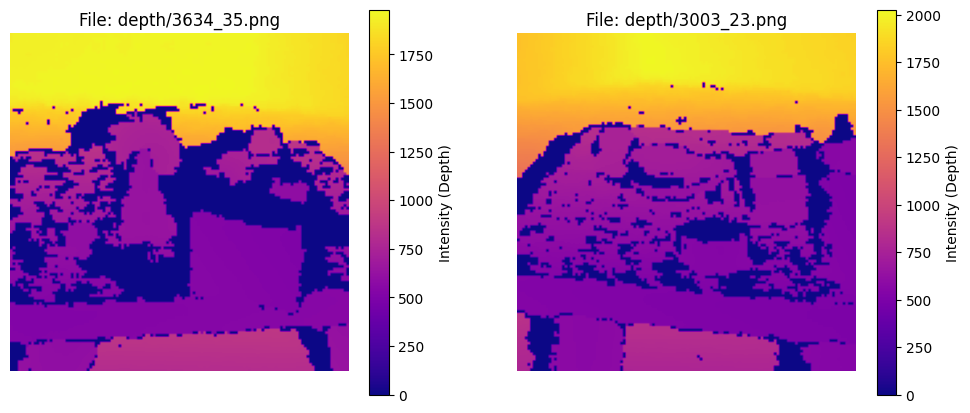

In [1]:
import tarfile
import io
import re
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
tar_path = "128x128/depth_128x128.tar.gz"
depth_pat = re.compile(r"depth/(\d{4})_(\d+)\.png")
samples = []

print(f"Opening {tar_path} for visualization...")

with tarfile.open(tar_path, "r:gz") as tar:
    # Iterate through members until we find 2 valid ones
    for member in tar:
        if depth_pat.match(member.name) and member.name != "depth/0000_00.png":
            f = tar.extractfile(member)
            if f:
                img = Image.open(io.BytesIO(f.read()))

                print("dtype:",np.array(img).dtype)
                print("min:", np.array(img).min())
                print("max:", np.array(img).max())
                print("mean:", np.array(img).mean())

                samples.append((member.name, img))
        
        if len(samples) >= 2:
            break

# Visualization logic
if samples:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for i, (name, img) in enumerate(samples):
        im = axes[i].imshow(img, cmap='plasma') # 'plasma' or 'magma' helps see depth gradients
        axes[i].set_title(f"File: {name}")
        axes[i].axis('off')
        plt.colorbar(im, ax=axes[i], label='Intensity (Depth)')
    plt.show()
else:
    print("No valid images found.")